---
---

# Estrellas de bosones con potencial cuadrático

---
---

## Elaborado por: 

Jacobo Alexander Calderón Ruiz

### Contacto: 

jacobo.calderon@correo.nucleares.unam.mx

## Asesor:

Darío Núñez Zúñiga

### Contacto:

nunez@nucleares.unam.mx

---

Este notebook corresponde al producto final del Servicio Social en el programa de Física de Altas Energías para la Facultad de Ciencias de la UNAM. Aquí podrás encontrar un código de Python para resolver las ***ecuaciones de Klein-Fok-Gordon*** (KFG) acopladas con las ***ecuaciones de campo de Einstein*** para un *espacio-tiempo estático* con *simetría esférica*. Al conjunto anterior de ecuaciones acopladas se les conoce como el ***sistema Einstein-Klein-Gordon*** (EKG) y su solución, considerando un campo escalar complejo, recibe el nombre en la literatura ***Estrellas de Bosones***. En este código se considera un potencial cuadrático.

### Librerías

El primer bloque de código corresponde a las bibliotecas. En particular, usaremos *scipy* (scientific Python) para resolver las ecuaciones diferenciales, *matplotlib* para la graficación de los resultados y *numpy* como auxiliar para definir algunos valores y arreglos matemáticos (como vectores, constantes matemáticas, listas, etc.). En el caso scipy, en especial utilizaremos su función `solve_bvp` para hallar la solución a un conjunto de ecuaciones diferenciales ordinarias (ODE's) de primer orden con condiciones de ligamiento y `cumulative_trapezoid` para integrar numéricamente usando el método del trapezoide. Una descripción detallada del funcionamiento de éstas funciones puede hallarse en el reporte del Servicio Social. La función `rcParams.update` nos permite seleccionar la configuración global de la paquetería *Matplotlib* sin el uso de abreviaciones; en este caso, definimos un tamaño de letra 12 y un estilo de letra *serif*.

In [1]:
# Librerías para el código
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
#from scipy.integrate import simpson
from scipy.integrate import solve_bvp
from scipy.integrate import cumulative_trapezoid

# Estilo para las gráficas
plt.rcParams.update({'font.size': 12, 'font.family': 'serif'})

### Sistema EKG

En la siguiente línea de código, definimos una función que será un arreglo vectorial de los parámetros de los campos deseados: $\Psi$, $\alpha$ y $\phi$ junto con sus derivadas. Para las expresiones de las derivadas, se utilizó uno de los códigos en Maple del asesor para dar la expresión del espacio-tiempo de acuerdo con la geometría deseada y de escribir las correspondientes ecuaciones de KFG acopladas con las ecuaciones de campo de Einstein. Posteriormente, éstas fueron reescritas para dar un sistema de ODE's de primer orden correspondientes con las entradas `L[3]`, `L[4]` y `L[5]`.

In [2]:
def EKG(r, v, p):
    # Definimos una función que tome los parámetros de la distancia (r), los valores del campo dados en forma vectorial (y) y
    # un vector p que representa el arreglo de parámetros a encontrar (eigenvalores)
    # Para el objetivo de este código el único parámetro es la frecuencia w, correspondiente a la entrada p[0]
    w = p[0] 
    
    # Factorizando m y redefiniendo omega/m -> omega y m*r-> r, adimensionales, es equivalente a m=1 con estas nueva r y omega
    #No es que seleccionamos la masa del bosón en unidades naturalizadas
    m = 1.0
    
    # Desempaquetamos el vector de valores de los campos para evaluarse en el sistema de ODE's
    Psi  = v[0]
    alpha = v[1]
    phi  = v[2]
    dPsi = v[3]
    dalpha = v[4]
    dphi = v[5]
    
    # Preparamos el vector de derivadas (misma forma que v)
    l = np.zeros_like(v)
    
    # Sus primeras componentes corresponden únicamente a las derivadas de primer orden
    l[0] = dPsi
    l[1] = dalpha
    l[2] = dphi
    
    # Mientras que las últimas componentes corresponden a las derivadas de segundo orden, es decir, las ecuaciones dinámicas
    l[3] = -np.pi * Psi**5 * ((w * phi / alpha)**2 + dphi**2 / Psi**4 + m**2 * phi**2) - (2.0 / r) * dPsi
    l[4] = 4.0 * np.pi * alpha * Psi**4 * (2.0 * w**2 / alpha**2 - m**2) * phi**2 - 2.0 * dalpha * dPsi / Psi - (2.0 / r) * dalpha
    l[5] = -(dalpha * dphi / alpha + 2.0 * dPsi * dphi / Psi) + Psi**4 * (m**2 - w**2 / alpha**2) * phi - (2.0 / r) * dphi

    # Regresamos el vector con el resultado de calcular las derivadas
    return l

### Condiciones de frontera

Aquí se definen las condiciones a la frontera; se escogen los extremos de la malla de integración, en este caso un punto cercano a cero (`ya`) y un punto en el "infinito" (`yb`), en donde se definen las condiciones de los campos que se deben cumplir en estos extremos. Particularmente el valor del campo escalar `phi0` se selecciona dependiendo de qué tan diluido queremos que sea a lo largo del espacio. Aquí escogimos un campo escalar muy disperso.

In [3]:
def bc(ya, yb, p):
    # ya: Estado en el origen (r = 1e-4)
    # yb: Estado en el "infinito" (radio máximo)
    
    phi0 = 0.0029003  # El valor inicial del campo escalar
    
    return np.array([
        # Condiciones en el origen (r -> 0)
        ya[2] - phi0,     # Fija phi(0) = phi0
        ya[3],            # dPsi(0) = 0
        ya[4],            # dalpha(0) = 0
        ya[5],            # dphi(0) = 0
        
        # Condiciones en infinito (r -> infinito)
        yb[0] - 1.0,      # Psi(inf) = 1
        yb[1] - 1.0,      # alpha(inf) = 1
        yb[2]             # phi(inf) = 0
    ])

### Malla de discretización y estimación inicial

Aquí se define: la malla numérica en la que se va a solucionar el sistema de ODE's, una matriz de prueba que contendrá todos los valores de los campos y sus derivadas ($M_{6 \times r_{mesh}}$), la estimación inicial y el valor de referencia para la frecuencia. Para la malla se parte desde un punto inicial muy cercano a cero (0.0001) y se termina en un valor en el "infinito" (100.0) realizando una discretización de 1000 puntos. Por otro lado, a diferencia de un método de shooting en el que se va integrando paso a paso sin una referencia, el solucionador bvp necesita partir de una estimación global previa, es decir, necesitamos darle una aproximación del comportamiento que van a tener los campos, para que pueda ir ajustando curvas que se aproximen a la solución exacta.

La estimación inicial se definió de la siguiente manera: se resuelve el sistema Schrödinger-Poisson (equivalente no-relativista del sistema EKG) y se encuentran los parámetros del potencial (`V0`) y la frecuencia de oscilación (`p_guess`); luego, usando coordenadas isotrópicas, se define el comportamiento de la métrica espacial a partir de una aproximación de campo débil usando el potencial Newroniano, mientras que la función métrica temporal se aproxima usando el potencial gravitatorio para una masa M y el campo escalar complejo se aproxima mediante una Gaussiana de amplitud $\phi_0$ y ancho 15.

In [4]:
# Valores inicial y final, así como la respectiva discretización de la malla
r_inf = 100.0
r_mesh = np.linspace(1e-4, r_inf, 1000)

# Matriz de estado inicial que contendrá todos los valores asociados a cada campo a lo largo de la malla
y_guess = np.zeros((6, r_mesh.size))

# Definimos la estimación inicial que le permitirá al solucionador buscar la solución exacta
V0 = -0.013957 # Potencial Newtoniano para el centro de la estrella
y_guess[0, :] = -V0/2. + 1.                  # Aproximación de campo débil para la curvatura espacial
y_guess[1, :] = (1. + (V0/2.)) / (1. - (V0/2.))  # Función de lapso en coordenadas isotrópicas de Schwartzschild en términos de V0
y_guess[2, :] = 0.0029003*np.exp(-(r_mesh/15.0)**2) # Usamos un perfil Gaussiano para phi, de modo que tenga una caída suave
                                                      # donde usamos un ancho de phi0 y un radio característico de 15.0

p_guess = np.array([0.9928]) # Tu frecuencia original como punto de partida

### Solucionador para una sola configuración

Aquí se ejecuta el solucionador mediante la función `solve_bvp` proporcionándole: las ecuaciones de los campos (`EKG`), las condiciones de ligamiento (`bc`), la malla numérica(`r_mesh`), la matriz de estado inicial (`y_guess`), el parámetro inicial (`p`); se define la tolerancia para hallar la solución, el número de nodos o puntos discretos máximos que puede añadir para encontrar la solución al sistema de ecuaciones y la verbosidad correspondiente al nivel de detalle mostrado a la hora de ejecutarse, seleccionada como detallada para el código. Posteriormente, se implementa un condicional para mostrar el valor de la frecuencia en caso de convergencia o mostrar un error en la solución si hay divergencia. Todo es implementado para hallar la **solución de una única estrella de bosones**.

In [26]:
# Ejecutamos el solucionador con los parámetros anteriormente definidos para hallar la frecuencia de la estrella de bosones
solucion = solve_bvp(EKG, bc, r_mesh, y_guess, p=p_guess, 
                     tol=1e-6, max_nodes=5000, verbose=2)

# Condicional para mostrar si hubo convergencia o no
if solucion.success:
    w_real = solucion.p[0] # Frecuencia de referencia de oscilación asociada a la estrella de bosones
    print(f"\n¡Convergencia lograda! La frecuencia del campo es w = {w_real:.6f}")
    
    # Extraemos la malla y todos los valores de las variables
    r_final = solucion.x # Guardamos la nueva malla numérica con los nodos que añadió la función
    Psi  = solucion.y[0]
    alpha    = solucion.y[1]
    phi  = solucion.y[2]
    dPsi = solucion.y[3]
    dalpha   = solucion.y[4]
    dphi = solucion.y[5]
    
    # Calculamos las masas ADM y de Komar, su diferencia y mostramos la masa asociada al campo escalar
    r_infinito = r_final[-1]
    dPsi_infinito = dPsi[-1]
    dalpha_infinito = dalpha[-1]
    M_ADM = -2.0 * (r_infinito**2) * dPsi_infinito
    M_komar = dalpha_infinito*r_infinito**2
    print(f"La diferencia entre masas ADM y de Komar es: {M_komar-M_ADM:.6f}")
    print(f"La masa total de la configuración es: M = {M_ADM:.6f}")
    
else:
    print("\nEl algoritmo no logró converger:", solucion.message)

   Iteration    Max residual  Max BC residual  Total nodes    Nodes added  
       1          7.40e-05       3.29e-27         1000             1       
       2          7.35e-05       4.30e-27         1001             1       
       3          7.25e-05       6.01e-31         1002             1       
       4          7.05e-05       1.12e-34         1003             1       
       5          6.69e-05       1.78e-35         1004             1       
       6          6.04e-05       2.04e-36         1005             1       
       7          5.02e-05       8.94e-37         1006             1       
       8          3.66e-05       2.02e-38         1007             1       
       9          2.22e-05       4.13e-39         1008             1       
      10          1.08e-05       4.59e-40         1009             1       
      11          3.97e-06       2.30e-40         1010             1       
      12          1.09e-06       5.51e-40         1011             1       
      13    

### Ajuste usando la aproximación de Robin

Si bien el solucionador ya nos proporciona las componentes de los campos métricos temporales y espaciales para la frecuencia solución, estos se ajustaron para las condiciones de frontera en el "infinito" que nosotros establecimos en la malla, no en el infinito real. Por ello, se utiliza una aproximación asintótica de los campos para que tengan la tendencia esperada en el infinito real.

In [27]:
# Solución con condición de frontera asintótica (Robin):
#   Psi - 1 ≈ M/(2r)  ->  r Psi' + (Psi - 1) = 0     en r = r_max
#   alpha - 1 ≈ -M/r  ->  r alpha' + (alpha - 1) = 0 en r = r_max

r_max_bc = solucion.x[-1]
FRAC_AJUSTE = 0.6   # el ajuste usa los puntos con r >= FRAC_AJUSTE * r_max

def ajuste_cola(r, f, frac=FRAC_AJUSTE):
    """Ajusta f(r) = A/r + B por mínimos cuadrados en r >= frac * r_max. Devuelve (A, B)."""
    mascara = r >= frac * r[-1]
    X = np.column_stack([1.0 / r[mascara], np.ones(mascara.sum())])   # columnas [1/r, 1]
    (A, B), *_ = np.linalg.lstsq(X, f[mascara], rcond=None)
    return A, B


def bc_robin(ya, yb, p):
    phi0 = 0.0029003
    return np.array([
        ya[2] - phi0, ya[3], ya[4], ya[5],
        r_max_bc * yb[3] + (yb[0] - 1.0),
        r_max_bc * yb[4] + (yb[1] - 1.0),
        yb[2],
    ])
 
sol_robin = solve_bvp(EKG, bc_robin, solucion.x, solucion.y, p=solucion.p,
                      tol=1e-6, max_nodes=50000, verbose=0)
 
if sol_robin.success:
    rb_ = sol_robin.x[-1]
    M_robin = -2.0 * rb_**2 * sol_robin.y[3][-1]
    print(f"Robin convergió | w = {sol_robin.p[0]:.6f} | M = {M_robin:.6f}")
    for nombre, f in [('Psi', sol_robin.y[0]), ('alpha', sol_robin.y[1])]:
        A, B = ajuste_cola(sol_robin.x, f)
        print(f"  Ajuste {nombre}: A = {A:.6f}, B = {B:.7f}   (B ≈ 1: tendencia esperada)")
else:
    print("Robin NO convergió:", sol_robin.message)


Robin convergió | w = 0.992950 | M = 0.204689
  Ajuste Psi: A = 0.102333, B = 1.0000001   (B ≈ 1: tendencia esperada)
  Ajuste alpha: A = -0.204118, B = 0.9999983   (B ≈ 1: tendencia esperada)


### Redefinimos las variables

Ya que el ajuste se realizó posteriormente, se redefinen las variables de acuerdo con las salidas de la aproximación de Robin.

In [28]:
# Reescribimos las variables en térmnos de la solución Robin para poder calcular
# la densidad, la compacidad y la masa total de la estrella de bosones
 
r_final = sol_robin.x
Psi, alpha, phi, dPsi, dalpha, dphi = sol_robin.y
w_real  = sol_robin.p[0]
M_ADM   = -2.0 * r_final[-1]**2 * dPsi[-1]
M_komar = dalpha[-1] * r_final[-1]**2
 
print(f"w = {w_real:.6f} | M_ADM = {M_ADM:.6f} | M_Komar = {M_komar:.6f}")


w = 0.992950 | M_ADM = 0.204689 | M_Komar = 0.204270


### Gráfica de los campos para la solución de una estrella de bosones

Aquí le mostramos al usuario el comportamiento de los campos a lo largo del espacio, tanto para la curvatura espacial $\Psi(r)$, la métrica $N(r)$ y el campo escalar $\phi(r)$.

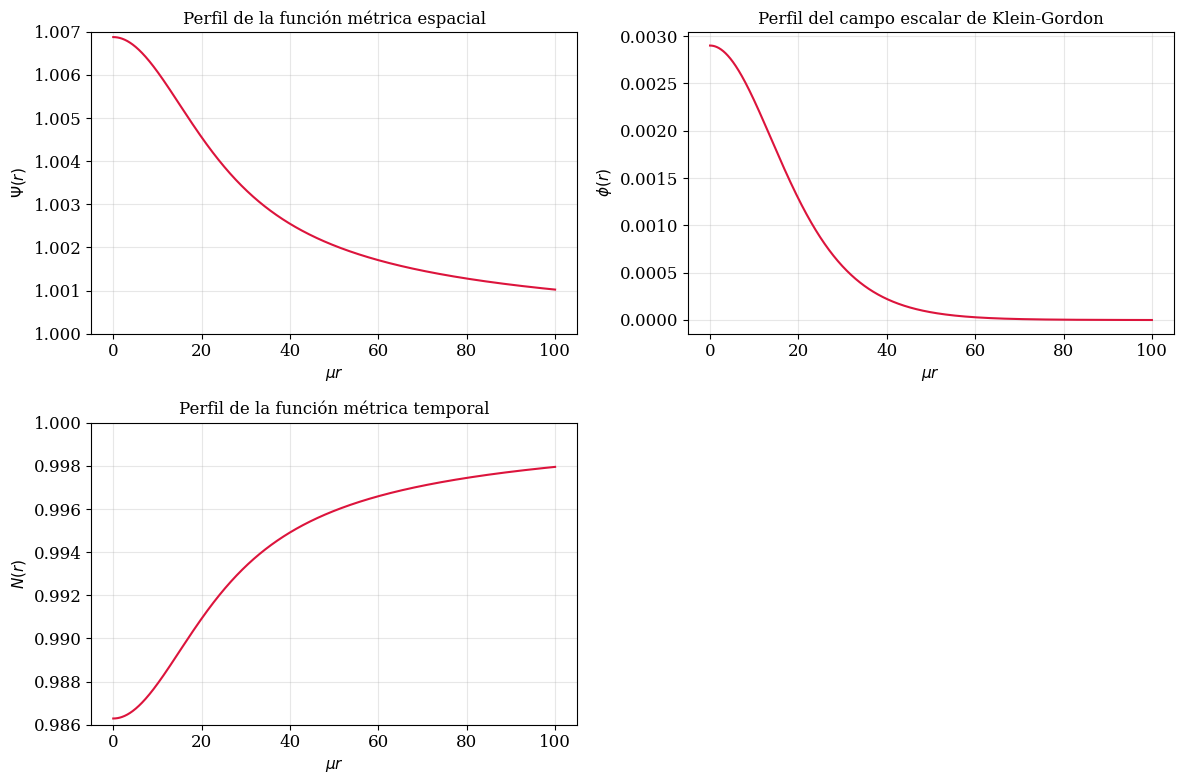

In [29]:
# Realizamos un arreglo para mostrar las gráficas correspondientes a los campos
# usando la solución con frontera asintótica (aproximación de Robin)
r_p = sol_robin.x

campos = [
    (sol_robin.y[0], r'\Psi', (0, 0), 'Perfil de la función métrica espacial'),
    (sol_robin.y[1], r'N',   (1, 0), 'Perfil de la función métrica temporal'),
    (sol_robin.y[2], r'\phi',(0, 1), 'Perfil del campo escalar de Klein-Gordon')
]

fig, ax = plt.subplots(2, 2, figsize=(12, 8))

for f, nom, pos, titulo in campos:
    ax[pos].plot(r_p, f, color='crimson', lw=1.5)
    ax[pos].set_title(titulo, fontsize=12)
    ax[pos].set_xlabel(r'$\mu r$', fontsize=11)
    ax[pos].set_ylabel(rf'${nom}(r)$', fontsize=11)
    ax[pos].grid(True, alpha=0.3)

# Desactivar el cuarto panel
ax[1, 1].axis('off')

#ax[0, 0].set_xlim(-5, 150)  # Escala ejes para Psi
ax[0, 0].set_ylim(1, 1.007)
#ax[1, 0].set_xlim(-5, 150)  # Escala ejes para Alpha
ax[1, 0].set_ylim(0.986, 1)
ax[1, 1].axis('off')

plt.tight_layout()
plt.savefig('Graficas_campos_B-Star_P2.png', dpi=300, bbox_inches='tight')
plt.show()

### Perfil de densidad y compacidad de la estrella

M asintótica (-2 r² dPsi) = 0.204689

[Misner-Sharp]
  M_total = 0.204688 | M99 = 0.202641
  R99 isotrópico = 47.0074 | R99 areal = 47.2121
  Compacidad C = M99/R99 = 0.00429

[Tipo ADM]
  M_total = 0.204688 | M99 = 0.202641
  R99 isotrópico = 47.0189 | R99 areal = 47.2236
  Compacidad C = M99/R99 = 0.00429


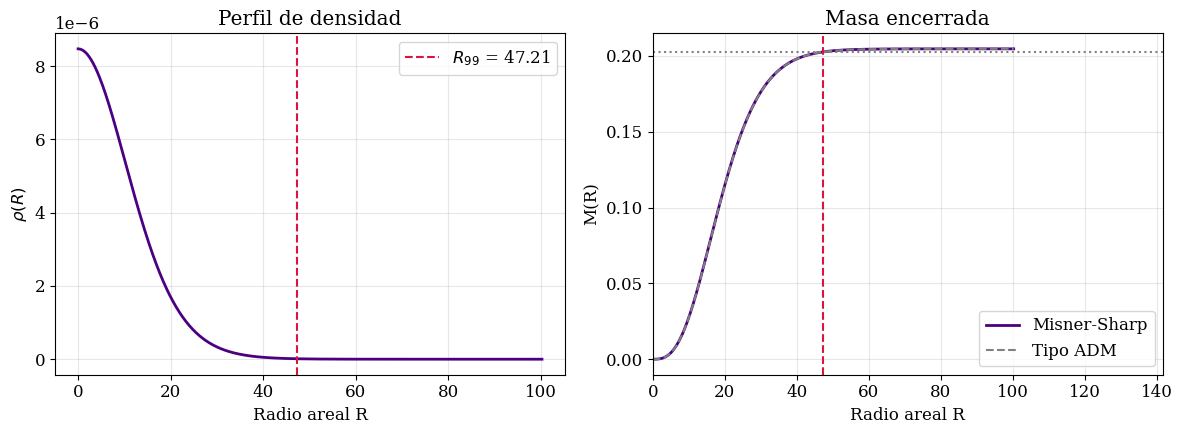

In [12]:
def densidad_masa_compacidad(r, Psi, alpha, phi, dphi, dPsi, w, m=1.0, fraccion=0.99):
    # 1) DENSIDAD desde los campos (punto de partida)
    rho = 0.5 * ((w*phi/alpha)**2 + dphi**2/Psi**4 + (m*phi)**2)

    # 2) Radio areal y su derivada
    R  = Psi**2 * r
    Rp = 2.0*Psi*dPsi*r + Psi**2          # dR/dr

    # 3) MASA por integración de rho (dos definiciones)
    M_MS  = cumulative_trapezoid(4*np.pi*rho*R**2*Rp,      r, initial=0.0)  # Misner-Sharp
    M_ADM = cumulative_trapezoid(4*np.pi*rho*Psi**5*r**2,  r, initial=0.0)  # tipo ADM

    # 4) M99, R99 y compacidad para cada masa ingresada
    def r99(M_r):
        M_tot = M_r[-1]; M99 = fraccion*M_tot
        r_99 = np.interp(M99, M_r, r)
        R_99 = np.interp(r_99, r, R)
        return M_tot, M99, r_99, R_99, M99/R_99

    return rho, R, M_MS, M_ADM, r99(M_MS), r99(M_ADM)
    
rho, R, M_MS, M_ADM, res_MS, res_ADM = densidad_masa_compacidad(
    r_final, Psi, alpha, phi, dphi, dPsi, w_real)

# Chequeo contra la masa ADM asintótica de solve_bvp
M_ADM_asint = -2.0*r_final[-1]**2*dPsi[-1]
print(f"M asintótica (-2 r² dPsi) = {M_ADM_asint:.6f}")

for nombre, (Mt, M99, r_99, R_99, C) in [("Misner-Sharp", res_MS), ("Tipo ADM", res_ADM)]:
    print(f"\n[{nombre}]")
    print(f"  M_total = {Mt:.6f} | M99 = {M99:.6f}")
    print(f"  R99 isotrópico = {r_99:.4f} | R99 areal = {R_99:.4f}")
    print(f"  Compacidad C = M99/R99 = {C:.5f}")

# Perfil de densidad + M(r)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(R, rho, color='indigo', lw=2)
ax[0].axvline(res_MS[3], color='crimson', ls='--', label=rf"$R_{{99}}$ = {res_MS[3]:.2f}")
#ax[0].set_yscale('log'); ax[0].set_ylim(1e-8*rho[0], 2*rho[0])
ax[0].set_xlabel('Radio areal R'); ax[0].set_ylabel(r'$\rho(R)$')
ax[0].set_title('Perfil de densidad'); ax[0].grid(True, alpha=0.3); ax[0].legend()

ax[1].plot(R, M_MS, color='indigo', lw=2, label='Misner-Sharp')
ax[1].plot(R, M_ADM, color='gray', lw=1.5, ls='--', label='Tipo ADM')
ax[1].axhline(res_MS[1], color='gray', ls=':')
ax[1].axvline(res_MS[3], color='crimson', ls='--')
ax[1].set_xlim(0, 3*res_MS[3]); ax[1].set_xlabel('Radio areal R'); ax[1].set_ylabel('M(R)')
ax[1].set_title('Masa encerrada'); ax[1].grid(True, alpha=0.3); ax[1].legend()
plt.tight_layout()
plt.savefig('Graficas_densidad_masa_B-Star_P2.png', dpi=300, bbox_inches='tight')
plt.show()

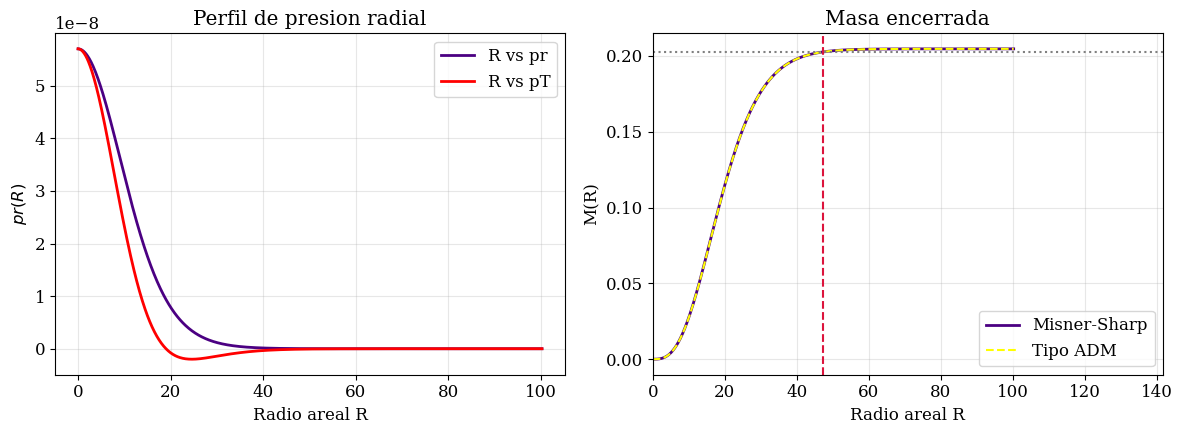

In [10]:
def presiones_condiciones(r, Psi, alpha, phi, dphi, dPsi, w, m=1.0, fraccion=0.99):
    # 1) DENSIDAD desde los campos (punto de partida)
    pr = 0.5 * (dphi**2/Psi**4 + ((w/alpha)**2 - m**2)*phi**2)
    pT = 0.5 * (-dphi**2/Psi**4 + ((w/alpha)**2 - m**2)*phi**2)
    ced = 0.5 * (dphi**2/Psi**4 + ((w/alpha)**2 +  m**2)*phi**2)
    cef = 0.5 * ((w/alpha)**2 -  m**2)*phi**2
    cen = 0.5 * (alpha**2*dphi**2/Psi**4 + (w*phi)**2)
    # 2) Radio areal y su derivada
    R  = Psi**2 * r
    Rp = 2.0*Psi*dPsi*r + Psi**2          # dR/dr

    # 3) MASA por integración de rho (dos definiciones)
    #M_MS  = cumulative_trapezoid(4*np.pi*rho*R**2*Rp,      r, initial=0.0)  # Misner-Sharp
    #M_ADM = cumulative_trapezoid(4*np.pi*rho*Psi**5*r**2,  r, initial=0.0)  # tipo ADM

    # 4) M99, R99 y compacidad para cada una
    #def r99(M_r):
     #   M_tot = M_r[-1]; M99 = fraccion*M_tot
     #  r_99 = np.interp(M99, M_r, r)
     #  R_99 = np.interp(r_99, r, R)
     #   return M_tot, M99, r_99, R_99, M99/R_99

    return pr, pT, ced, cef, cen, R

pr, pT, ced, cef, cen, R = [], [], [], [], [], []
    
pr, pT, ced, cef, cen, R = presiones_condiciones(
    r_final, Psi, alpha, phi, dphi, dPsi, w_real)


# Chequeo contra la masa ADM asintótica de solve_bvp
#M_ADM_asint = -2.0*r_final[-1]**2*dPsi[-1]
#print(f"M asintótica (-2 r² dPsi) = {M_ADM_asint:.6f}")

#for nombre, (Mt, M99, r_99, R_99, C) in [("Misner-Sharp", res_MS), ("Tipo ADM", res_ADM)]:
#    print(f"\n[{nombre}]")
 #   print(f"  M_total = {Mt:.6f} | M99 = {M99:.6f}")
  #  print(f"  R99 isotrópico = {r_99:.4f} | R99 areal = {R_99:.4f}")
   # print(f"  Compacidad C = M99/R99 = {C:.5f}")

# Perfil de densidad + M(r)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(R, pr, color='indigo', lw=2, label="R vs pr")
ax[0].plot(R, pT, color='red', lw=2, label="R vs pT")
#ax[0].axvline(res_MS[3], color='crimson', ls='--', label=rf"$R_{{99}}$ = {res_MS[3]:.2f}")
#ax[0].set_yscale('log'); ax[0].set_ylim(1e-8*rho[0], 2*rho[0])
ax[0].set_xlabel('Radio areal R'); ax[0].set_ylabel(r'$pr(R)$')
ax[0].set_title('Perfil de presion radial'); ax[0].grid(True, alpha=0.3); ax[0].legend()

ax[1].plot(R, M_MS, color='indigo', lw=2, label='Misner-Sharp')
ax[1].plot(R, M_ADM, color='yellow', lw=1.5, ls='--', label='Tipo ADM')
ax[1].axhline(res_MS[1], color='gray', ls=':')
ax[1].axvline(res_MS[3], color='crimson', ls='--')
ax[1].set_xlim(0, 3*res_MS[3]); ax[1].set_xlabel('Radio areal R'); ax[1].set_ylabel('M(R)')
ax[1].set_title('Masa encerrada'); ax[1].grid(True, alpha=0.3); ax[1].legend()
plt.tight_layout(); plt.show()

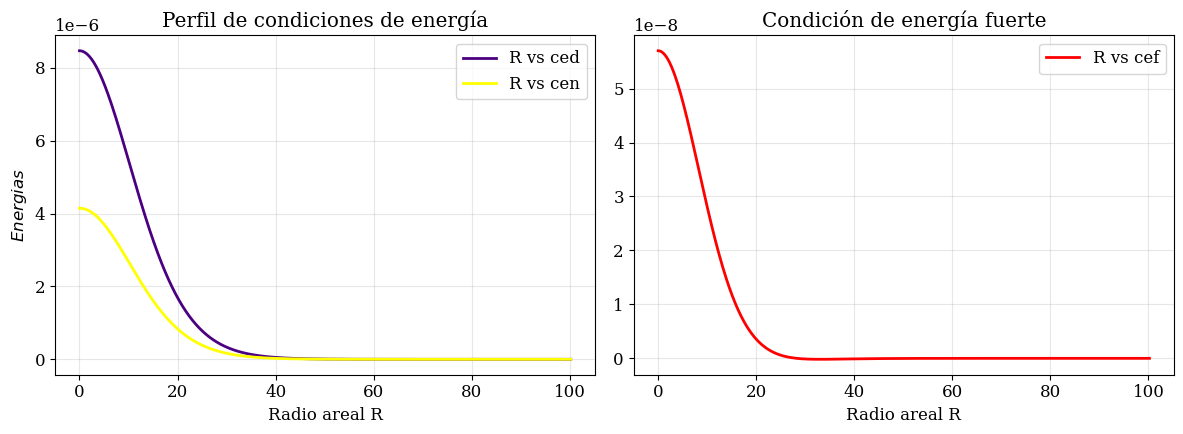

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(R, ced, color='indigo', lw=2, label="R vs ced")
ax[1].plot(R, cef, color='red', lw=2, label="R vs cef")
ax[0].plot(R, cen, color='yellow', lw=2, label="R vs cen")
#ax[0].axvline(res_MS[3], color='crimson', ls='--', label=rf"$R_{{99}}$ = {res_MS[3]:.2f}")
#ax[0].set_yscale('log'); ax[0].set_ylim(1e-8*rho[0], 2*rho[0])
ax[0].set_xlabel('Radio areal R'); ax[0].set_ylabel(r'$Energias$')
ax[0].set_title('Perfil de condiciones de energía'); ax[0].grid(True, alpha=0.3); ax[0].legend()
ax[1].set_xlabel('Radio areal R'); ax[0].set_ylabel(r'$Energias$')
ax[1].set_title('Condición de energía fuerte'); ax[1].grid(True, alpha=0.3); ax[1].legend()

plt.tight_layout(); plt.show()

Procedimiento para calcular la masa y radio de la estrella
Usaremos el valor de la masa y el de la compacidad obtenidos. En el caso de la masa, de hecho lo que obtuvimos es el producto m*M, con 
m el valor de la masa del bosón y M la masa de la estrella; m se factorizó en todas las ecuaciones y se normalizó la distancia a una distancia adimensional m*r, así como con la frecuencia w obtenida. Más aún las constantes físicas no están puestas explícitamente. Al ponerlas el producto m*M se transforma a (m_\phi*c/hbar)*(M*G/c^2), con m_phi la masa del bosón, la partícula del campo escalar, c la velocidad de la luz, hbar la constante Planck reducida y G la constante de gravitación universal. De hecho, m es una cantidad con unidades de inverso de distancia por lo que se puede pensar como m=1/lambda_phi, con lambda_phi la longitud de Compton del campo escalar. Y M*G/c^2 es una cantidad con unidades de distancia (en el caso de hoyos negros sería la mitad del radio del horizonte). En todo caso, hay que notar que el producto m*M es adimensional.

Para obtener entonces el valor de la masa de la estrella en unidades físicas, digamos masas solares, hay que elegir el valor de la masa del bosón, de su longitud de Compton, que querramos considerar. Es usual no dar la masa sino la energía en reposo del bosón, por lo que la razón obtenida (m_\phi*c/hbar)*(M*G/c^2) multiplicamos y dividimos por c: (m_\phi*c^2/hbar)*(M*G/c^3) y le damos el valor a m_\phi*c^2, la energía en reposo, que se quiera considerar. Sea entonces m_\phi*c^2=10^(-n) eV, en el caso de axiones n=5 -10, para campos ultraligeron n=22, 23. Con ello tenemos que el producto m*M toma la forma m*M=10^(-n)*p*M_Sol*G/(hbar*c^3), donde hemos expresado a la masa de la estrella de bosones como un múltiplo de la masa solar, p*M_Sol. Con los valores de las constantes universales, c=2.99*10^5 km/s, hbar=6.5821*10^(-16) eV*s y G=6.67*10^(-11) m^3/kg/s^2 = 1.34*10^(11) km^3/M_sol/s^2 (véase el trabajo "On the detectability of gravitational waves emitted from head-on collisions of l-boson stars" de Mariana Lira, Laura O. Villegas, Javier M. Antelis, Víctor Jaramillo, Claudia Moreno y Darío Núñez, General Relativity and Gravitation (2025) 57:68
https://doi.org/10.1007/s10714-025-03397-y para más detalles) obtenemos que el producto m*M toma el valor m*M=7.6151*p*10^(-n + 9), con lo que obtenemos finalmente que p=(m*M)/7.6151*10^(n-9)=1.33*10^(n-10)*(m*M). El parámetro m en términos del exponente n toma la forma: m=10^(-n)/(c*hbar)=5.08*10^(9-n)/km. La masa del bosón m_phi=1.77*10^(-n) kg. La longitud de Compton es el inverso, lambda_phi=1.96*10^(n-10) km. Para la frecuencia angular omega, obtenemos, w=omega/(m*c), de donde omega=w*(m*c)=w*10^(-n)/hbar=w*1.51*10^(15 - n) hertz. Para determinar el radio de la estrella, usamos el dato de la compacidad, C=M/R, poniéndo unidades C=p*M_Sol*G/c^2/R, usando la expresión para p obtenemos R=1.96*10^(n-10)*(m*M/C) km.

Resumen: 
Dado w, (m*M) y C, considerando al bosón con energía en reposo 10^(-n) eV obtenemos
1. parámetro m = 5.08*10^(9-n)/km
2. Longitud de Compton: lambda_phi= 1.96*10^(n-10) km
3. Masa del bosón m_phi=1.77*10^(-n) kg
4. Frecuencia angular de oscilación, omega = w*1.51*10^(15 - n) hertz
5. Masa de la estrella, en múltiplos de masa solar, p*M_Sol, p=1.33*10^(n-10)*(m*M)
6. Radio de la estrella, R =1.96*10^(n-10)*(m*M)/C km 

En el caso presentado, obtuvimos M99 = 0.202641, de acuerdo a lo discutido esto implica que m*M=0.202641, w = 0.992950 y para la compacidad tenemos C=0.00429. Si elegimos un campo escalar con energía en reposo de 10^(-5) eV, un axión, n=5, tenemos que
m=5.08*10^4/km
Longitud de Compton: lambda_phi= 1.96*10^(-5) km
Masa del bosón m_phi= 1.77*10^(-5) kg
omega=1.499*10^(10) hertz
p=2.695*10^(-5)
R=9.25*10^(-4) km

Un objeto de casi un metro, 0.916 m, con una masa de 2.69 cienmilésimas del Sol, formado por un campo escalar pesado, con masa de 1.77*10^(-5) kg y oscilando a 1.49*10^(10) hertz. Cuando se postularon las estrellas de bosones se consideraba al campo escalar describiendo a los axiones, que tienen esa energía en reposo, del orden de 10^(-5) eV, por lo que se obtenían estrellas con estas configuraciones de masa y radio y se les llamó mini boson stars.  Pero el campo escalar puede tomar valores en un rango muy amplio, para el mismo caso presentado pero para un caso ultraligero, 10^(-22) eV, n=22 obtenemos
m=5.08*10^(-13)/km
Longitud de Compton: lambda_phi= 1.96*10^(12) km
Masa del bosón m_phi= 1.77*10^(-22) kg
omega=1.499*10^(-7) hertz
p=2.695*10^(12)
R=9.25*10^(13) km

¡Es un objeto astrofísico! con una masa de 10^(12) masas solares, que es la de un halo de materia obscura, con un radio enorme, de 9.16*10^(13) km, 2.96 pc (sería como el núcleo del halo, pero con toda su masa)

Se pueden hacer otras combinaciones, si lo que se desea es un objeto de una masa solar, escogemos p=1 en m*M=7.6151*p*10^(-n + 9), para la configuración presentada m*M=0.202641, por lo que n=9.6 y entonces tenemos
m=1.276/km
Longitud de Compton: lambda_phi= 0.78 km
Masa del bosón m_phi= 4.44*10^(-10) kg
omega=3.76*10^5 hertz
p=1.07
R=36.85 km

Una estrella de 1.07 masas solares con un radio de 36.48 km. Si quisiéramo un halo, con un radio de 15 kpc = 4.62*10^(17) km y con 10^12 masas solares, entonces tenemos una compacidad de C=10^(12) (M_Sol*G/c^2)/(4.62*10^17 km)=1.48*10^12 km/(4.62*10^17 km)=3.2*10^(-6). Esta compacidad tan baja corresponde a una w muy cercana a 1, fuera del rango donde hemos calculado. Pero, una vez que se determina esa w, digamos 0.9999999, se ve el correspondiente valor m*M de la configuración, también muy pequeño, digamos, 10^(-4) y, como ya dimos el valor de p=10^10, ahora m*M=7.6151*p*10^(-n + 9) implica 10^(-4)=7.6151*10^(12)*10^(-n + 9), lo que nos dá una n del orden de 25. 

En el código se puede poner en esta parte 
¿Qué valor de la energía en reposo quieres considerar? Dar n:
Y ya que imprima las correspondientes
1. parámetro m = 5.08*10^(9-n)/km
2. Longitud de Compton: lambda_phi= 1.96*10^(n-10) km
3. Masa del bosón m_phi=1.77*10^(-n) kg
4. Frecuencia angular de oscilación, omega = w*1.51*10^(15 - n) hertz
5. Masa de la estrella, en múltiplos de masa solar, p*M_Sol, p=1.33*10^(n-10)*(m*M)
6. Radio de la estrella, R =1.96*10^(n-10)*(m*M)/C km 

In [13]:
# masa del boson = m_phi, parámetro mu es la m del código
n = int(input("Ingresa el orden de la potencia para la energía en reposo (sugerimos un valor entero entre 22 y 5):"))

mu = 5.08*10.0**(9-n) # 1/kilómetro
l_comp = 1.96*10.0**(n-10) # en kilómetros
m_boson = 1.77*10.0**(-n) # en kilogramos
omega = w_real*1.51*10.0**(15-n) # en hertz
p = 1.33*10.0**(n-10) # valor adimensional
masa_estrella = p # en múltiplos de la masa solar
radio_estrella = 1.96*10.0**(n-10)*M_ADM_asint/C # en kilómetros

print(f"""Los parámetros físicos de la estrella de bosones con frecuencia solucion igual a {w_real:.6f} son: 
Parámetro: \u03BC = {mu:.3e} km^(-1)
Longitud de Compton: \u03BB_\u03C0 = {l_comp:.3e} km
Masa del boson: m = {m_boson:.3e} kg
Frecuencia angular de oscilación: \u03C9 = {omega:.3e} hz
Masa de la estrella de bosones: M = {p:.3e} M_solares
Radio de la estrella: R = {radio_estrella:.3e} km
""")

Ingresa el orden de la potencia para la energía en reposo (sugerimos un valor entero entre 22 y 5): 6


Los parámetros físicos de la estrella de bosones con frecuencia solucion igual a 0.992950 son: 
Parámetro: μ = 5.080e+03 km^(-1)
Longitud de Compton: λ_π = 1.960e-04 km
Masa del boson: m = 1.770e-06 kg
Frecuencia angular de oscilación: ω = 1.499e+09 hz
Masa de la estrella de bosones: M = 1.330e-04 M_solares
Radio de la estrella: R = 9.349e-03 km



### Definición para realizar gráficas

In [33]:
# Función para graficar los campos con el ajuste A/r + B en la cola
 
def graficar_campos(r, Psi, N, phi, titulo=None):

    fig, ax = plt.subplots(2, 2, figsize=(12, 8))

    campos = [
        (Psi, r'\Psi', (0, 0), 'Perfil de la función métrica radial'),
        (N, r'N', (1, 0), 'Perfil de la función de lapso'),
        (phi, r'\phi', (0, 1), 'Perfil del campo escalar')
    ]

    for f, nom, pos, nombre in campos:
        ax[pos].plot(r, f, color='crimson', lw=1.5)
        ax[pos].set_title(nombre, fontsize=12)
        ax[pos].set_xlabel(r'$\mu r$')
        ax[pos].set_ylabel(rf'${nom}(r)$')
        ax[pos].grid(True, alpha=0.3)

    ax[1, 1].axis('off')

    if titulo:
        fig.suptitle(titulo, fontsize=13)

    fig.tight_layout()
    plt.show()

### Solucionador para varias configuraciones

En este apartado lo que se realiza es una generalización del solucionador, pero ahora aplicado a todo un conjunto de valores iniciales del campo escalar $\phi$. De esta manera, se encuentren las frecuencias de oscilación, los valores de los campos, las masas y la malla numérica para cada una de las soluciones del solucionador a cada valor inicial de $\phi$. Su estructura general es: se define un arreglo de valores del campo escalar, partiendo del valor de `phi0` de la aproximación de Robin, se define un conjunto de listas para guardar los valores encontrados, se copian las soluciones del caso para una única estrella de bosones y se implementa un condicional `for` para hallar toda la familia de estrellas de bosones. En total se calcularon 400 estrellas para una crear una curva suave, pero este valor puede ser modificado para hallar un mayor número de soluciones.

In [31]:
# Definimos un conjunto de valores del campo phi, utilizando como valor inicial la aproximación de Robin y subimos gradualmente 
# hasta el régimen inestable para obtener estrellas de bosones con frecuencias diferentes
phi0_array = np.linspace(0.0029003, 0.4, 400)

# Definimos listas para guardar los datos encontrados para calcular las masas
masas_lista, delta_masas = [], []
frecuencias_lista, r_lista = [], []
Psi_lista, alpha_lista, phi_lista = [], [], []
dPsi_lista, dphi_lista = [], []
R99_MS_lista, M99_MS_lista, C_MS_lista = [], [], []
R99_ADM_lista, M99_ADM_lista, C_ADM_lista = [], [], []
rho_lista, R_lista = [], []
M_MS_lista,M_ADM_lista = [], []

# Renombramos la malla y los valores iniciales para intercambiarlos por los resultados del solucionador de una estrella
r_mesh_actual  = sol_robin.x.copy()
y_guess_actual = sol_robin.y.copy()
p_guess_actual = sol_robin.p.copy()

# Creamos un bucle para obtener los datos asociados a cada estrella de bosones
for i, phi_central in enumerate(phi0_array):

    # Creamos una función de frontera local para ir seleccionando los diferentes valores del campo phi
    def bc_dinamica(ya, yb, p, phi_central=phi_central):
        return np.array([
            ya[2] - phi_central, ya[3], ya[4], ya[5],
            r_max_bc * yb[3] + (yb[0] - 1.0),     # Psi   ~ 1 + M/(2r)
            r_max_bc * yb[4] + (yb[1] - 1.0),     # alpha ~ 1 - M/r
            yb[2],
        ])

    # Ejecutamos el solucionador
    sol = solve_bvp(EKG, bc_dinamica, r_mesh_actual, y_guess_actual, p=p_guess_actual,
                    tol=1e-5, max_nodes=50000, verbose=0)

    # Definimos un condicional para identificar si la convergencia fue exitosa o no
    if not sol.success:
        print(f"Fallo en convergencia para phi0 = {phi_central}. Deteniendo bucle.")
        break

    # --- Extraer variables de la solución actual ---
    r_sol   = sol.x
    Psi     = sol.y[0]
    alpha   = sol.y[1]
    phi     = sol.y[2]
    dPsi    = sol.y[3]
    dalpha  = sol.y[4]
    dphi    = sol.y[5]
    w_sol   = sol.p[0]
    
    # Valores en el infinito para el cálculo de la masa ADM y de Komar
    M_adm_i   = -2.0 * r_sol[-1]**2 * dPsi[-1]
    M_komar_i =  dalpha[-1] * r_sol[-1]**2

    # --- Cálculo de perfiles de densidad, masa y compacidad ---
    rho, R, M_MS, M_ADM, res_MS, res_ADM = densidad_masa_compacidad(
        r_sol, Psi, alpha, phi, dphi, dPsi, w_sol
    )

    # Desempaquetado de res_MS: (M_tot, M99, r_99, R_99, C)
    _, M99_ms, _, R99_ms, C_ms = res_MS
    _, M99_adm, _, R99_adm, C_adm = res_ADM

    # Guardar métricas globales de esta estrella
    R99_MS_lista.append(R99_ms)
    M99_MS_lista.append(M99_ms)
    C_MS_lista.append(C_ms)
    
    R99_ADM_lista.append(R99_adm)
    M99_ADM_lista.append(M99_adm)
    C_ADM_lista.append(C_adm)

    rho_lista.append(rho.copy())
    R_lista.append(R.copy())
    M_MS_lista.append(M_MS.copy())
    M_ADM_lista.append(M_ADM.copy())

    # Almacenamos resultados en diferentes listas
    r_lista.append(r_sol.copy())
    Psi_lista.append(sol.y[0].copy())
    alpha_lista.append(sol.y[1].copy())
    phi_lista.append(sol.y[2].copy())
    dPsi_lista.append(sol.y[3].copy())
    dphi_lista.append(sol.y[5].copy())
 
    frecuencias_lista.append(sol.p[0])
    masas_lista.append(M_adm_i)
    delta_masas.append(M_komar_i - M_adm_i)

    # Esta opción es para ir mostrando las configuraciones solución
    #print(f"Estrella {i+1:02d}/{len(phi0_array)} | phi0 = {phi_central:.4f} | w = {w_actual:.5f} | M = {M_actual:.4f}")
    
    # Usamos la solución de esta estrella como la estimación inicial de la siguiente
    # de modo que, al usar estrellas contiguas muy similares, la convergencia sea más rápida.
    r_mesh_actual  = sol.x.copy()
    y_guess_actual = sol.y.copy()
    p_guess_actual = sol.p.copy()

print(f"Estrellas calculadas: {len(frecuencias_lista)}")

Estrellas calculadas: 400


### Gráfica para la familia de soluciones encontrada

En esta línea, a partir de los resultados de la celda anterior, se realiza una gráfica de las frecuencias y masas de las estrellas de bosones encontradas, cuyo resultado corresponde con una forma similar a un "caracol" o "rizo", siendo la zona estable la que comprende valores de aproximadamente 0.85 a 1 y la zona de inestabilidad donde se comienza a formar el rizo.

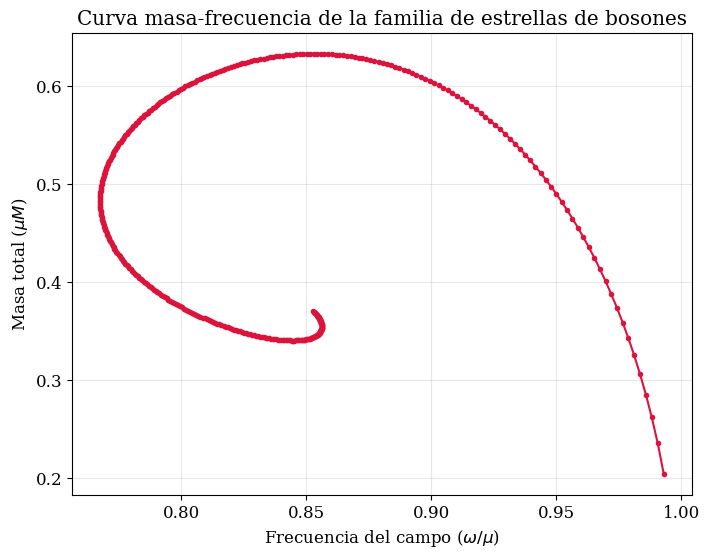

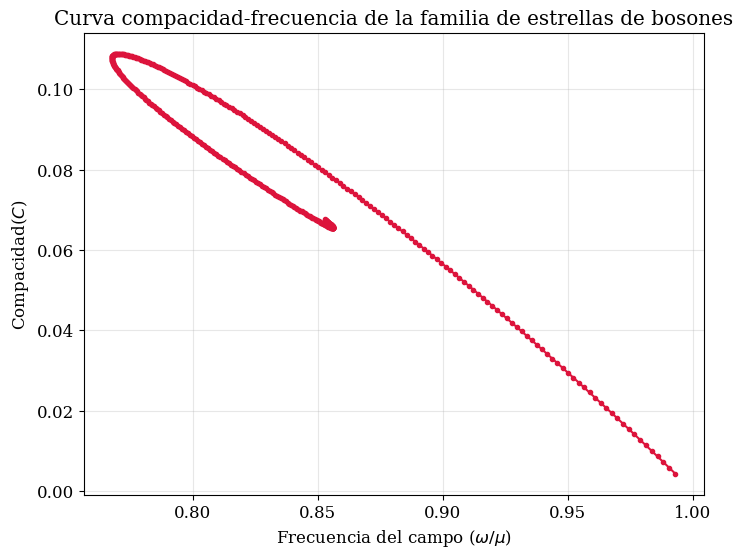

In [32]:
# Realización de la gráfica: Masa (M) vs Frecuencia (w) para todas las estrellas de bosones encontradas

plt.figure(figsize=(8, 6))
plt.plot(frecuencias_lista, masas_lista, color='crimson', marker='.', linestyle='-', linewidth=1.5)
plt.title('Curva masa-frecuencia de la familia de estrellas de bosones')
plt.xlabel(r'Frecuencia del campo ($\omega/\mu$)')
plt.ylabel(r'Masa total ($\mu M$)')
plt.grid(True, alpha=0.3) # 
plt.savefig('Grafica-masa-frecuencia-B-Star_P2.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 6))
plt.plot(frecuencias_lista,C_ADM_lista, color='crimson', marker='.', linestyle='-', linewidth=1.5)
plt.title('Curva compacidad-frecuencia de la familia de estrellas de bosones')
plt.xlabel(r'Frecuencia del campo ($\omega/\mu$)')
plt.ylabel(r'Compacidad($C$)')
plt.grid(True, alpha=0.3) # 
plt.savefig('Grafica-compacidad-frecuencia-B-Star_P2.png', dpi=300, bbox_inches='tight')
plt.show()

### Selección de parámetros

En este apartado se muestra al usuario todos los parámetros asociados a una solución de estrella de bosones de toda la familia calculada, de acuerdo con los valores que se muestran en la gráfica anterior. Lo primero que se debe hacer es escoger un valor de interés para la frecuencia, luego el programa te muestra, de acuerdo con la solución del sistema, los 6 valores más cercanos al seleccionado y sus respectivas masas asociadas para que selecciones uno. Posteriormente, se muestran los valores de la masa ADM y las gráficas de los campos asociados a la frecuencia de tu elección, así como el perfil de densidad y la compacidad de la estrella.


¡Hola!

Mi función es mostrarte los valores del campo, la densidad, masa acumulada y 
compacidad asociados a un valor particular de la frecuencia de tu interés.


 Rango de frecuencias disponibles: [0.76755, 0.99295]


Valor de la frecuencia aproximado:  0.95



 Los valores más cercanos a la frecuencia que proporcionaste son:

1. Frecuencia = 0.95004 | Masa ADM = 0.48985 | Compacidad C = 0.02947
2. Frecuencia = 0.94792 | Masa ADM = 0.49738 | Compacidad C = 0.03067
3. Frecuencia = 0.95217 | Masa ADM = 0.48192 | Compacidad C = 0.02826
4. Frecuencia = 0.94582 | Masa ADM = 0.50456 | Compacidad C = 0.03186
5. Frecuencia = 0.95431 | Masa ADM = 0.47359 | Compacidad C = 0.02704
6. Frecuencia = 0.94373 | Masa ADM = 0.51140 | Compacidad C = 0.03303



 ¿Cuál de estos conjuntos deseas consultar? (introduce el número de la opción):  5



   PROPIEDADES DE LA ESTRELLA DE BOSONES (w = 0.95431)
 Frecuencia central (w/μ):       0.954312
 Masa ADM asintótica:          0.473586
 Masa M99 (Misner-Sharp):      0.468823
 Radio R99 areal:              17.3411
 COMPACIDAD (C = M99 / R99):   0.02704



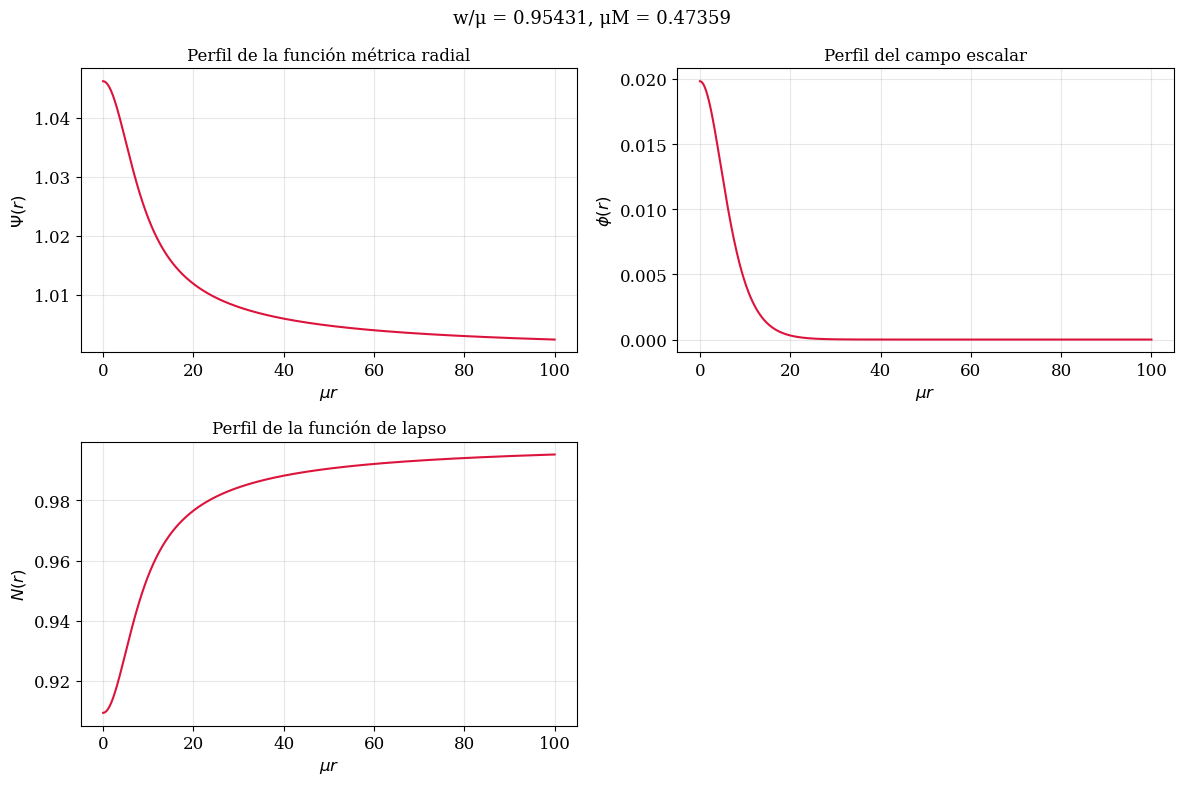

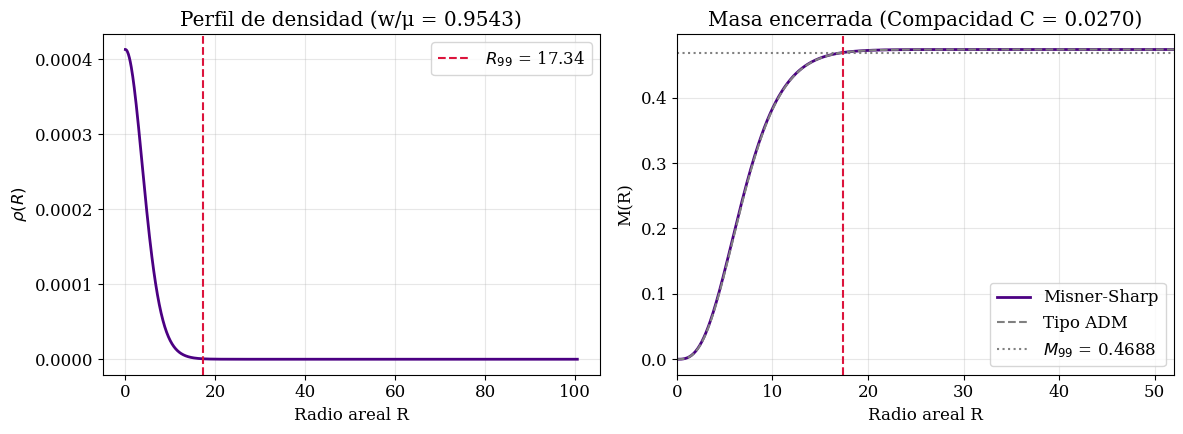


 ¿Deseas buscar otra frecuencia? (s/n):  n



¡Hasta luego!


In [34]:
# Selección de parámetros
criterio = 's'

# Identificación de la frecuencia mínima obtenida en la secuencia
w_min = min(frecuencias_lista)
w_max = max(frecuencias_lista)

print('''
¡Hola!

Mi función es mostrarte los valores del campo, la densidad, masa acumulada y 
compacidad asociados a un valor particular de la frecuencia de tu interés.
''')

while criterio == 's':

    print(f'\n Rango de frecuencias disponibles: [{w_min:.5f}, {w_max:.5f}]')
    frecuencia = float(input('Valor de la frecuencia aproximado: '))

    # ---------------------------------------------------------
    # Validación de la frecuencia mínima accesible
    # ---------------------------------------------------------
    if frecuencia < w_min:
        print(
            f'\n [ERROR] La frecuencia ingresada (w = {frecuencia:.5f}) es inferior a '
            f'la frecuencia mínima calculada en la secuencia (w_mín = {w_min:.6f}). '
            'No existen configuraciones físicamente válidas por debajo de este límite.'
        )
        criterio = input('\n¿Deseas buscar con otra frecuencia? (s/n): ').lower()
        continue
    elif frecuencia > w_max:
        print(
            f'\n [ERROR] La frecuencia ingresada (w = {frecuencia:.5f}) es superior a '
            f'la frecuencia máxima calculada en la secuencia (w_max = {w_max:.6f}). '
            'No existen configuraciones físicamente válidas por debajo de este límite.'
        )
        criterio = input('\n¿Deseas buscar con otra frecuencia? (s/n): ').lower()
        continue

    # ---------------------------------------------------------
    # Buscar las posiciones de los 6 valores más cercanos
    # ---------------------------------------------------------
    posiciones_cercanas = sorted(
        range(len(frecuencias_lista)),
        key=lambda i: abs(frecuencias_lista[i] - frecuencia)
    )[:6]

    # ---------------------------------------------------------
    # Mostrar las opciones al usuario
    # ---------------------------------------------------------
    print('\n Los valores más cercanos a la frecuencia que proporcionaste son:\n')

    for numero, posicion in enumerate(posiciones_cercanas, start=1):
        print(
            f'{numero}. '
            f'Frecuencia = {frecuencias_lista[posicion]:.5f} | '
            f'Masa ADM = {masas_lista[posicion]:.5f} | '
            f'Compacidad C = {C_MS_lista[posicion]:.5f}'
        )

    # ---------------------------------------------------------
    # Preguntar cuál de las opciones desea consultar
    # ---------------------------------------------------------
    opcion = int(
        input(
            '\n ¿Cuál de estos conjuntos deseas consultar? '
            '(introduce el número de la opción): '
        )
    )

    # ---------------------------------------------------------
    # Validar opción elegida y extraer datos sin recalcular
    # ---------------------------------------------------------
    if 1 <= opcion <= len(posiciones_cercanas):

        posicion = posiciones_cercanas[opcion - 1]

        # 1. Extracción directa de escalares y perfiles desde las listas guardadas
        w_sel      = frecuencias_lista[posicion]
        M_adm_sel  = masas_lista[posicion]
        C_ms_sel   = C_MS_lista[posicion]
        R99_ms_sel = R99_MS_lista[posicion]
        M99_ms_sel = M99_MS_lista[posicion]

        rho_sel    = rho_lista[posicion]
        R_sel      = R_lista[posicion]
        M_MS_sel   = M_MS_lista[posicion]
        M_ADM_sel  = M_ADM_lista[posicion]

        # 2. Despliegue formal de métricas y compacidad en consola
        print('\n' + '='*55)
        print(f'   PROPIEDADES DE LA ESTRELLA DE BOSONES (w = {w_sel:.5f})')
        print('='*55)
        print(f' Frecuencia central (w/μ):       {w_sel:.6f}')
        print(f' Masa ADM asintótica:          {M_adm_sel:.6f}')
        print(f' Masa M99 (Misner-Sharp):      {M99_ms_sel:.6f}')
        print(f' Radio R99 areal:              {R99_ms_sel:.4f}')
        print(f' COMPACIDAD (C = M99 / R99):   {C_ms_sel:.5f}')
        print('='*55 + '\n')

        # 3. Gráfica de campos métricos y de materia
        graficar_campos(
            r_lista[posicion],
            Psi_lista[posicion],
            alpha_lista[posicion],
            phi_lista[posicion],
            titulo=f"w/μ = {w_sel:.5f}, μM = {M_adm_sel:.5f}"
        )

        # 4. Gráficas de Perfil de Densidad y Masa Encerrada (usando las listas)
        fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

        # Perfil de densidad rho(R)
        ax[0].plot(R_sel, rho_sel, color='indigo', lw=2)
        ax[0].axvline(R99_ms_sel, color='crimson', ls='--', label=rf"$R_{{99}}$ = {R99_ms_sel:.2f}")
        ax[0].set_xlabel('Radio areal R')
        ax[0].set_ylabel(r'$\rho(R)$')
        ax[0].set_title(f'Perfil de densidad (w/μ = {w_sel:.4f})')
        ax[0].grid(True, alpha=0.3)
        ax[0].legend()

        # Masa encerrada M(R)
        ax[1].plot(R_sel, M_MS_sel, color='indigo', lw=2, label='Misner-Sharp')
        ax[1].plot(R_sel, M_ADM_sel, color='gray', lw=1.5, ls='--', label='Tipo ADM')
        ax[1].axhline(M99_ms_sel, color='gray', ls=':', label=rf"$M_{{99}}$ = {M99_ms_sel:.4f}")
        ax[1].axvline(R99_ms_sel, color='crimson', ls='--')
        ax[1].set_xlim(0, 3 * R99_ms_sel)
        ax[1].set_xlabel('Radio areal R')
        ax[1].set_ylabel('M(R)')
        ax[1].set_title(f'Masa encerrada (Compacidad C = {C_ms_sel:.4f})')
        ax[1].grid(True, alpha=0.3)
        ax[1].legend()

        plt.tight_layout()
        plt.show()

    else:
        print('\n La opción seleccionada no es válida.')

    # ---------------------------------------------------------
    # Preguntar si desea realizar otra búsqueda
    # ---------------------------------------------------------
    criterio = input('\n ¿Deseas buscar otra frecuencia? (s/n): ').lower()

print('\n¡Hasta luego!')

### Para el cálculo de los parámetros físicos

In [17]:
# Selección de parámetros
criterio = 's'

# Identificación de la frecuencia mínima obtenida en la secuencia
c_min = min(C_ADM_lista)
c_max = max(C_ADM_lista)

print('''
¡Hola!

Selecciona una compacidad para la estrella de bosones, de acuerodo con los valores de la gráfica anterior, para mostrarte sus parámetros físicos asociados.
''')

while criterio == 's':

    print(f'\nRango de compacidades disponibles: [{c_min:.5f}, {c_max:.5f}]')
    compacidad = float(input('Valor de la compacidad aproximado: '))

    # ---------------------------------------------------------
    # Validación de la compacidad mínima y máxima accesible
    # ---------------------------------------------------------
    if compacidad < c_min:
        print(
            f'\n[ERROR] La compacidad ingresada (C = {compacidad:.5f}) es inferior a '
            f'la compacidad mínima calculada en la secuencia (w_mín = {c_min:.6f}). '
            'No existen configuraciones físicamente válidas por debajo de este límite.'
        )
        criterio = input('\n¿Deseas buscar con otra compacidad? (s/n): ').lower()
        continue
    elif compacidad > c_max:
        print(
            f'\n[ERROR] La compacidad ingresada (C = {compacidad:.5f}) es superior a '
            f'la compacidad máxima calculada en la secuencia (c_mín = {c_min:.6f}). '
            'No existen configuraciones físicamente válidas por encima de este límite.'
        )
        criterio = input('\n¿Deseas buscar con otra compacidad? (s/n): ').lower()
        continue

    # ---------------------------------------------------------
    # Buscar las posiciones de los 6 valores más cercanos
    # ---------------------------------------------------------
    posiciones_cercanas = sorted(
        range(len(C_ADM_lista)),
        key=lambda i: abs(C_ADM_lista[i] - compacidad)
    )[:6]

    # ---------------------------------------------------------
    # Mostrar las opciones al usuario
    # ---------------------------------------------------------
    print('\nLos valores más cercanos a la compacidad que proporcionaste son:\n')

    for numero, posicion in enumerate(posiciones_cercanas, start=1):
        print(
            f'{numero}. '
            f'Compacidad C = {C_ADM_lista[posicion]:.5f} | '
            f'Frecuencia = {frecuencias_lista[posicion]:.5f} | '
        )

    # ---------------------------------------------------------
    # Preguntar cuál de las opciones desea consultar
    # ---------------------------------------------------------
    opcion = int(
        input(
            '\n¿Cuál de estos conjuntos deseas consultar? '
            '(introduce el número de la opción): '
        )
    )

    # ---------------------------------------------------------
    # Validar opción elegida y extraer datos sin recalcular
    # ---------------------------------------------------------
    if 1 <= opcion <= len(posiciones_cercanas):

        posicion = posiciones_cercanas[opcion - 1]

        criterio2 = "s"

        while criterio2 == "s":
            
            n = int(input("Ingresa el orden de la potencia para la energía en reposo (sugerimos un valor entero entre 22 y 5):"))
            
            mu = 5.08*10.0**(9-n) # 1/kilómetro
            l_comp = 1.96*10.0**(n-10) # en kilómetros
            m_boson = 1.77*10.0**(-n) # en kilogramos
            omega = frecuencias_lista[posicion]*1.51*10.0**(15-n) # en hertz
            p = 1.33*10.0**(n-10) # valor adimensional
            masa_estrella = p # en múltiplos de la masa solar
            radio_estrella = 1.96*10.0**(n-10)*M99_ADM_lista[posicion]/C_ADM_lista[posicion] # en kilómetros
            
            print(f"""Los parámetros físicos de la estrella de bosones con frecuencia solucion igual a {frecuencias_lista[posicion]:.6f} son: 
            Parámetro: \u03BC = {mu:.3e} km^(-1)
            Longitud de Compton: \u03BB_\u03C0 = {l_comp:.3e} km
            Masa del boson: m = {m_boson:.3e} kg
            Frecuencia angular de oscilación: \u03C9 = {omega:.3e} hz
            Masa de la estrella de bosones: M = {p:.3e} M_solares
            Radio de la estrella: R = {radio_estrella:.3e} km
            """)

            criterio2 = str(input("¿Desear ingresar otra potencia? (s/n): ")).lower()

    else:
        print('\nLa opción seleccionada no es válida.')

    # ---------------------------------------------------------
    # Preguntar si desea realizar otra búsqueda
    # ---------------------------------------------------------
    criterio = input('\n¿Deseas buscar otra compacidad? (s/n): ').lower()

print('\n¡Hasta luego!')


¡Hola!

Selecciona una compacidad para la estrella de bosones, de acuerodo con los valores de la gráfica anterior, para mostrarte sus parámetros físicos asociados.


Rango de compacidades disponibles: [0.00429, 0.10886]


Valor de la compacidad aproximado:  0.005



Los valores más cercanos a la compacidad que proporcionaste son:

1. Compacidad C = 0.00429 | Frecuencia = 0.99295 | 
2. Compacidad C = 0.00575 | Frecuencia = 0.99054 | 
3. Compacidad C = 0.00717 | Frecuencia = 0.98818 | 
4. Compacidad C = 0.00859 | Frecuencia = 0.98582 | 
5. Compacidad C = 0.00999 | Frecuencia = 0.98348 | 
6. Compacidad C = 0.01137 | Frecuencia = 0.98115 | 



¿Cuál de estos conjuntos deseas consultar? (introduce el número de la opción):  4
Ingresa el orden de la potencia para la energía en reposo (sugerimos un valor entero entre 22 y 5): 6


Los parámetros físicos de la estrella de bosones con frecuencia solucion igual a 0.985821 son: 
            Parámetro: μ = 5.080e+03 km^(-1)
            Longitud de Compton: λ_π = 1.960e-04 km
            Masa del boson: m = 1.770e-06 kg
            Frecuencia angular de oscilación: ω = 1.489e+09 hz
            Masa de la estrella de bosones: M = 1.330e-04 M_solares
            Radio de la estrella: R = 6.450e-03 km
            


¿Desear ingresar otra potencia? (s/n):  n

¿Deseas buscar otra compacidad? (s/n):  n



¡Hasta luego!
